# Setup

In [13]:
import os
import numpy as np
import matplotlib.pyplot as plt
%matplotlib ipympl
from Util.util import load_keypoints_and_labels,angle_between_vectors,get_segment_borders
from Util.pulltest_util import get_axis_velocity, fill_short_runs
from scipy.signal import find_peaks

In [14]:
recording_name = "tug2"
filename_stereo = os.path.join("data", recording_name, recording_name + "_stereo.npz")
filename_qualisys = os.path.join("data", recording_name, recording_name + "_qualisys.npz")
stereo_keypoints, stereo_labels = load_keypoints_and_labels(filename=filename_stereo)
qualisys_keypoints, qualisys_labels = load_keypoints_and_labels(filename=filename_qualisys)

q_cut_1 = 900
s_cut_1 = 1000
q_cut_2 = q_cut_1 + len(stereo_keypoints) - s_cut_1 #TODO: this only works if the qualisys recoridng is longer than the stereo
baseline_end = 400
fps = 100

qualisys_keypoints = qualisys_keypoints[q_cut_1:q_cut_2,:,:]
stereo_keypoints = stereo_keypoints[s_cut_1:,:,:]

loaded data from: data\tug2\tug2_stereo.npz with keys: ['labels', 'keypoints']
loaded data from: data\tug2\tug2_qualisys.npz with keys: ['labels', 'keypoints']


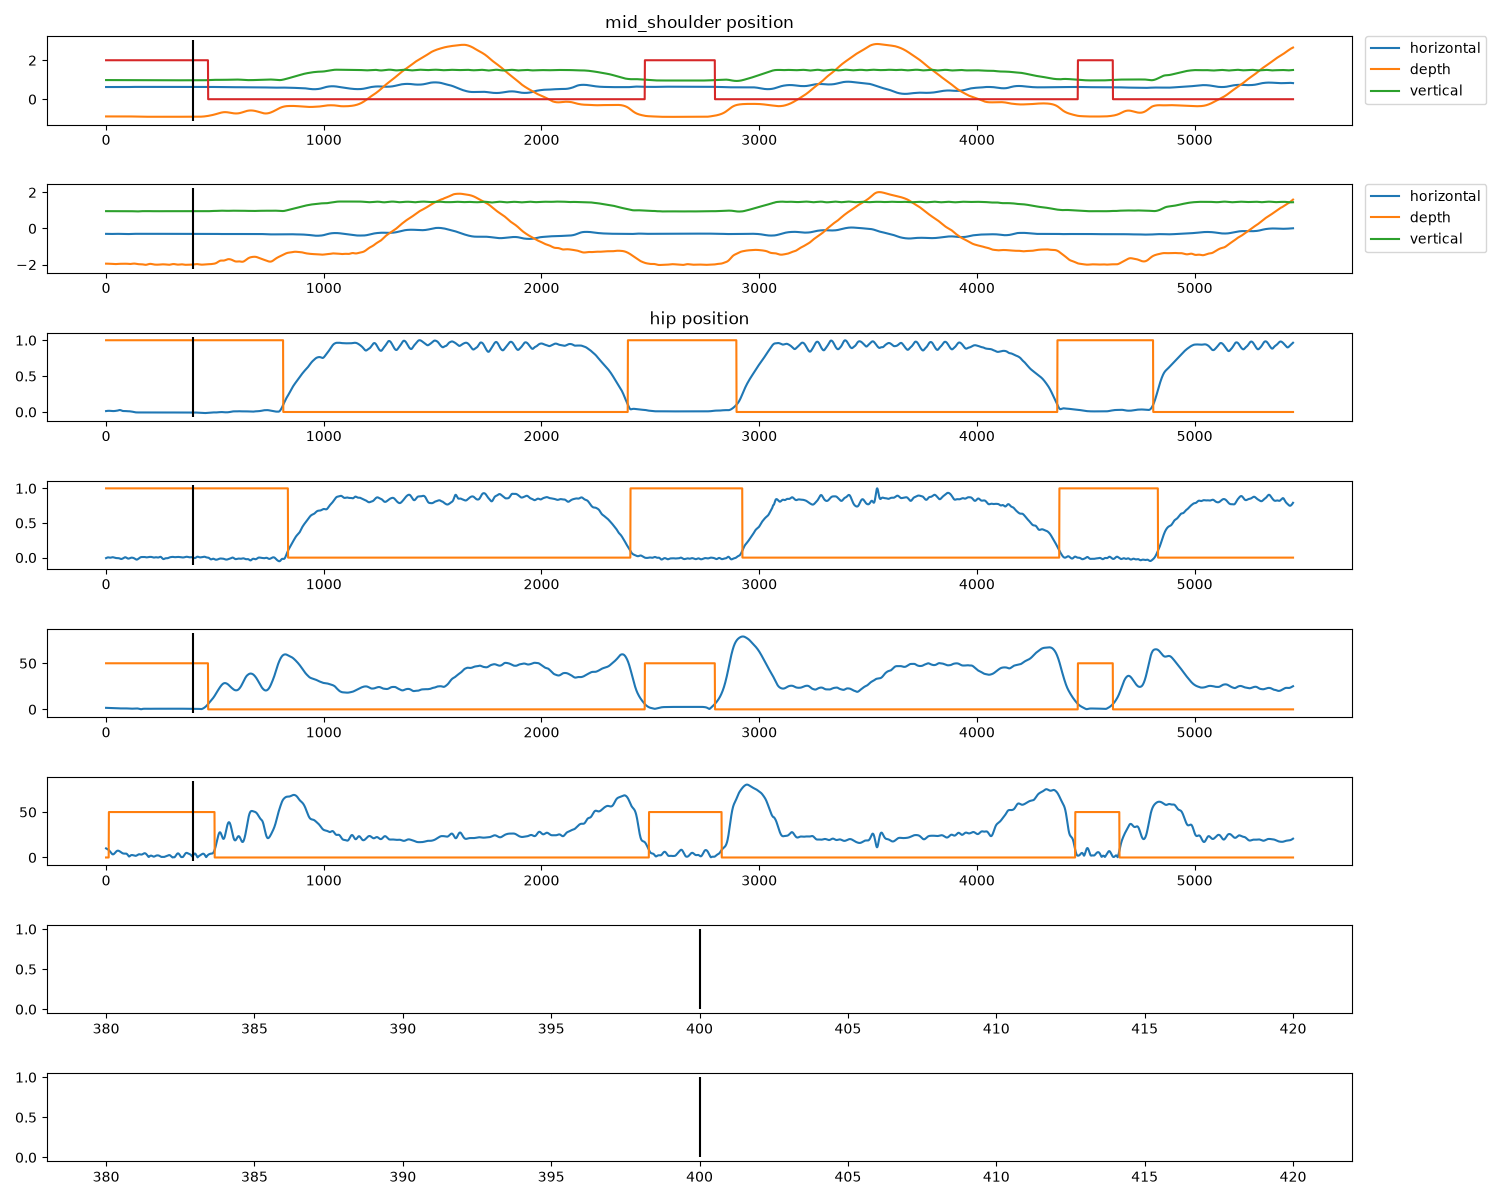

In [22]:
# qualisys_shoulder_vector = np.gradient(qualisys_keypoints[:,qualisys_labels.index('left_shoulder'),0]-qualisys_keypoints[:,qualisys_labels.index('right_shoulder'),0], axis=0)
# stereo_shoulder_vector = np.gradient(stereo_keypoints[:,stereo_labels.index('left_shoulder'),0]-stereo_keypoints[:,stereo_labels.index('right_shoulder'),0], axis=0)

#lean angle
qualisys_trunk = qualisys_keypoints[:,qualisys_labels.index("mid_shoulder"),:] - qualisys_keypoints[:, qualisys_labels.index("mid_hip"),:]
qualisys_trunk_baseline = np.nanmean(qualisys_trunk[:baseline_end], axis=0)
qualisys_trunk_angle = np.array([angle_between_vectors(trunk_vector, qualisys_trunk_baseline) for trunk_vector in qualisys_trunk])
qualisys_trunk_angle_baseline = np.nanmean(qualisys_trunk_angle[:baseline_end])
qualisys_trunk_near_baseline = np.abs(qualisys_trunk_angle-qualisys_trunk_angle_baseline<5)
qualisys_trunk_near_baseline = fill_short_runs(qualisys_trunk_near_baseline.astype(np.int8), value=0, min_length=50).astype(bool)


stereo_trunk = stereo_keypoints[:,stereo_labels.index("mid_shoulder"),:] - stereo_keypoints[:, stereo_labels.index("mid_hip"),:]
stereo_trunk_baseline = np.nanmean(stereo_trunk[:baseline_end], axis=0)
stereo_trunk_angle = np.array([angle_between_vectors(trunk_vector, stereo_trunk_baseline) for trunk_vector in stereo_trunk])
stereo_trunk_angle_baseline = np.nanmean(stereo_trunk_angle[:baseline_end])
stereo_trunk_near_baseline = np.abs(stereo_trunk_angle-stereo_trunk_angle_baseline<5)
stereo_trunk_near_baseline = fill_short_runs(stereo_trunk_near_baseline.astype(np.int8), value=0, min_length=50).astype(bool)




# hip position
qualisys_hip = qualisys_keypoints[:,qualisys_labels.index('mid_hip'),2]
qualisys_hip_baseline = np.nanmean(qualisys_hip[:baseline_end])
qualisys_hip = qualisys_hip-qualisys_hip_baseline
qualisys_hip = qualisys_hip/np.nanmax(qualisys_hip)
qualisys_hips_down = np.abs(qualisys_hip) < 0.1   # within 10% of the sit-to-stand range
qualisys_baseline_segments = list(get_segment_borders(qualisys_hips_down))



stereo_hip = stereo_keypoints[:,stereo_labels.index('mid_hip'),2]
stereo_hip_baseline = np.nanmean(stereo_hip[:baseline_end])
stereo_hip = stereo_hip - stereo_hip_baseline
stereo_hip = stereo_hip/np.nanmax(stereo_hip)
stereo_hips_down = np.abs(stereo_hip) < 0.1   # within 10% of the sit-to-stand range
stereo_baseline_segments = list(get_segment_borders(stereo_hips_down))



plt.close('all')
fig, axs = plt.subplots(8,1,figsize=(15,12))
axs[0].set_title('mid_shoulder position')
axs[0].plot(qualisys_keypoints[:,qualisys_labels.index('mid_shoulder'),:], label=['horizontal','depth','vertical'])
axs[0].plot((qualisys_hips_down & qualisys_trunk_near_baseline)*2)
axs[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)
axs[1].plot(stereo_keypoints[:,stereo_labels.index('mid_shoulder'),:], label=['horizontal','depth','vertical'])
axs[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)

axs[2].set_title('hip position')
axs[2].plot(qualisys_hip)
axs[2].plot(qualisys_hips_down)
axs[3].plot(stereo_hip)
axs[3].plot(stereo_hips_down)

axs[4].plot(qualisys_trunk_angle)
axs[4].plot(qualisys_trunk_near_baseline*50)
axs[5].plot(stereo_trunk_angle)
axs[5].plot(stereo_trunk_near_baseline*50)



for ax in axs:
    y_min, y_max = ax.get_ylim()
    ax.vlines(baseline_end, y_min, y_max, 'k')
    # for segment_border in qualisys_baseline_segments:

    #     ax.vlines(segment_border, y_min, y_max)
    # ax.vlines(5280, y_min, y_max)

plt.tight_layout()